<a href="https://colab.research.google.com/github/indicadorel-ui/SimulacionComputacionalyAnalisisdeResultados/blob/main/Simulaci%C3%B3n_Computacional_y_An%C3%A1lisis_de_Resultados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea 3. Simulación Computacional y Análisis de Resultados
## Simulación Monte Carlo de tiempos de espera en atención al cliente

**Curso:** Simulación Estocástica  
**Docente:** Dr. Gerónimo Quiñonez Barraza
<br>
**Alumno:** Ing. Jesús Emmanuel Vázquez Macías
<br>
**Módulos:** 9, 10 y 11  
**Herramienta:** Python (Google Colab)  
**Semilla aleatoria:** 42  
**Número de simulaciones:** 1,000

## 1. Descripción del problema

Una empresa desea estimar cuánto esperan sus clientes antes de ser atendidos. Los tiempos de espera varían entre clientes y no siempre pueden predecirse con exactitud. Para estudiar este comportamiento, se simularán 1,000 tiempos de espera independientes.

El objetivo es estimar el tiempo promedio de espera, describir la variabilidad observada y cuantificar la incertidumbre de la media mediante un intervalo de confianza del 95 %. Los resultados pueden orientar decisiones sobre la capacidad de atención y la necesidad de reducir demoras.

### Supuestos del modelo

- El tiempo de espera se representa con una **distribución exponencial**, común en modelos sencillos de tiempos entre eventos.
- Se supone una media teórica de **8 minutos** por cliente. Es un valor hipotético para ilustrar el método, no un dato medido de una empresa real.
- Cada observación representa un cliente y se considera independiente de las demás.
- Se simulan 1,000 observaciones usando la semilla 42 para que el experimento sea reproducible.

La distribución exponencial tiene un único parámetro de escala, que en este caso es la media esperada. El modelo es una simplificación: no representa explícitamente horarios pico, distintas filas ni prioridades de atención.

## 2. Simulación

Se fija la semilla aleatoria en 42 y se generan 1,000 valores. El resultado se expresa en minutos. Al volver a ejecutar el notebook, se obtendrá la misma muestra mientras se mantengan el código y las versiones compatibles de las bibliotecas.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Parámetros de la simulación
SEMILLA = 42
N = 1_000
MEDIA_TEORICA = 8  # minutos

# Generador reproducible y simulación de tiempos de espera
rng = np.random.default_rng(SEMILLA)
tiempos_espera = rng.exponential(scale=MEDIA_TEORICA, size=N)

# Tabla de datos: una fila por cliente simulado
datos = pd.DataFrame({
    "Cliente simulado": np.arange(1, N + 1),
    "Tiempo de espera (minutos)": tiempos_espera
})

print(f"Observaciones generadas: {len(datos):,}")
print(f"Semilla utilizada: {SEMILLA}")
datos.head()

Observaciones generadas: 1,000
Semilla utilizada: 42


,Cliente simulado,Tiempo de espera (minutos)
0,1,19.233669
1,2,18.689517
2,3,19.078088
3,4,2.238354
4,5,0.691499


## 3. Análisis estadístico

Se calcularán la media, la desviación estándar muestral, el mínimo y el máximo. Para estimar un intervalo de confianza del 95 % para la media se utiliza la distribución *t* de Student:

$$
\bar{x} \pm t_{0.975,\,n-1}\frac{s}{\sqrt{n}}
$$

donde $\bar{x}$ es la media muestral, $s$ la desviación estándar muestral y $n$ el tamaño de la muestra.

El intervalo cuantifica la incertidumbre de la estimación de la media; no significa que el 95 % de los clientes espere dentro de esos límites.

In [ ]:
# Estadísticos descriptivos
media = tiempos_espera.mean()
desviacion = tiempos_espera.std(ddof=1)  # desviación estándar muestral
minimo = tiempos_espera.min()
maximo = tiempos_espera.max()

# Intervalo de confianza bilateral del 95 % para la media
n = len(tiempos_espera)
error_estandar = desviacion / np.sqrt(n)
t_critico = stats.t.ppf(0.975, df=n - 1)
margen_error = t_critico * error_estandar
ic_inferior = media - margen_error
ic_superior = media + margen_error

resultados = pd.DataFrame({
    "Estadístico": [
        "Número de simulaciones",
        "Media (minutos)",
        "Desviación estándar muestral (minutos)",
        "Mínimo (minutos)",
        "Máximo (minutos)",
        "Error estándar de la media (minutos)",
        "IC 95 % — límite inferior (minutos)",
        "IC 95 % — límite superior (minutos)"
    ],
    "Resultado": [
        n, media, desviacion, minimo, maximo, error_estandar,
        ic_inferior, ic_superior
    ]
})

resultados.style.format({"Resultado": "{:,.3f}"})

,Estadístico,Resultado
0,Número de simulaciones,"1,000.000"
1,Media (minutos),8.115
2,Desviación estándar muestral (minutos),8.221
3,Mínimo (minutos),0.009
4,Máximo (minutos),59.765
5,Error estándar de la media (minutos),0.260
6,IC 95 % — límite inferior (minutos),7.605
7,IC 95 % — límite superior (minutos),8.625


## 4. Presentación gráfica

El histograma muestra la frecuencia de los tiempos simulados. La línea vertical indica la media observada y la línea discontinua representa la media teórica de 8 minutos. La forma asimétrica a la derecha es característica de la distribución exponencial.

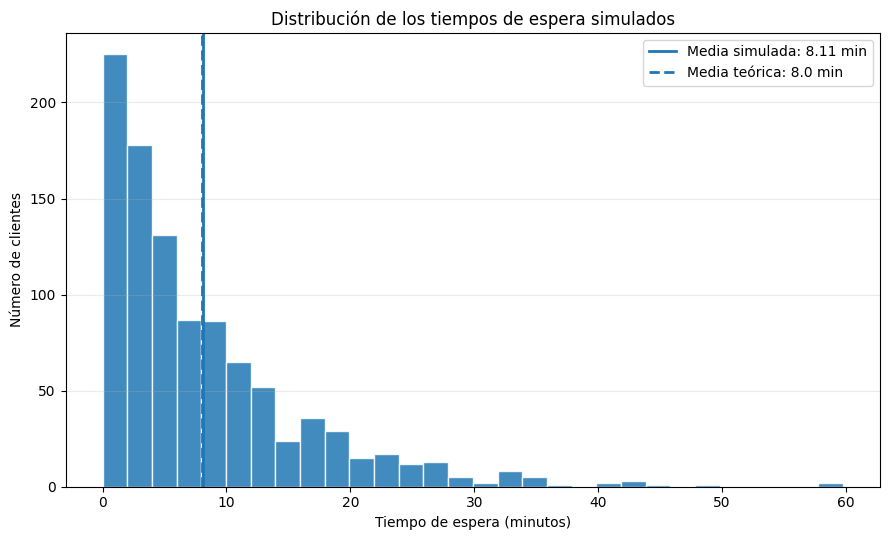

In [ ]:
plt.figure(figsize=(9, 5.5))
plt.hist(tiempos_espera, bins=30, edgecolor="white", alpha=0.85)
plt.axvline(media, linewidth=2, label=f"Media simulada: {media:.2f} min")
plt.axvline(MEDIA_TEORICA, linestyle="--", linewidth=2,
            label=f"Media teórica: {MEDIA_TEORICA:.1f} min")

plt.title("Distribución de los tiempos de espera simulados")
plt.xlabel("Tiempo de espera (minutos)")
plt.ylabel("Número de clientes")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Interpretación de resultados

La media simulada es una estimación del tiempo promedio de espera bajo los supuestos del modelo. Es razonable que no sea exactamente igual a los 8 minutos teóricos: la simulación utiliza una muestra finita y, por tanto, presenta variación aleatoria.

La desviación estándar describe cuánto varían los tiempos entre clientes. El mínimo y el máximo muestran los valores extremos observados en esta muestra; no deben interpretarse como límites garantizados del sistema. El intervalo de confianza del 95 % proporciona un rango plausible para la media poblacional, considerando la incertidumbre de muestreo y los supuestos del modelo.

### ¿Cómo se podrían usar estos resultados?

La empresa podría comparar la media estimada y su intervalo con una meta de servicio (por ejemplo, una espera promedio máxima aceptable). Si el promedio o el límite superior del intervalo supera la meta, sería razonable investigar medidas como aumentar personal en periodos de alta demanda o simplificar el proceso de atención. Para una decisión operativa real, primero habría que calibrar la distribución con datos históricos y considerar la variación por hora y día.

## 6. Conclusión

La simulación Monte Carlo permitió generar de forma reproducible 1,000 tiempos de espera y resumirlos mediante estadísticos descriptivos y un intervalo de confianza del 95 %. El ejercicio muestra cómo la aleatoriedad produce diferencias entre la media simulada y la media teórica, y cómo el intervalo de confianza ayuda a expresar la incertidumbre de la estimación. Los resultados sirven como una primera aproximación para analizar un servicio, aunque las decisiones reales requieren datos observados y un modelo que represente mejor las condiciones de operación.